<a href="https://colab.research.google.com/github/leonIceHot/Computer-Vision-Course/blob/main/CH0_%E5%BD%B1%E5%83%8F%E7%B9%AA%E8%A3%BD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1.影像畫布與坐標系基石 (The Canvas & Coordinate System)

## OpenCV 坐標系 vs. 矩陣行列

NumPy .shape 輸出 (H, W, C): (250, 400, 3)


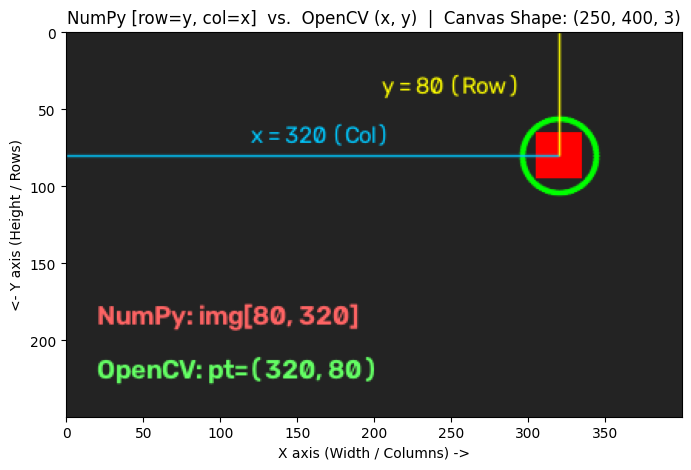

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. 建立畫布：NumPy 使用 (Height, Width, Channels)
# ==========================================
H, W = 250, 400  # 高度 250 (y上限), 寬度 400 (x上限)
canvas = np.zeros((H, W, 3), dtype=np.uint8)
canvas[:, :] = (35, 35, 35)  # 深灰底色

# 我們鎖定一個目標空間點：水平 x = 320, 垂直 y = 80
target_x = 320
target_y = 80

# ==========================================
# 2. 使用 NumPy 切片操作：順序必須是 [y (Row), x (Col)]
# ==========================================
# 將目標點周圍 30x30 的區域塗成紅色 (BGR: 0, 0, 255)
# 若寫成 canvas[target_x, target_y] 會因為 320 > 高度250 而直接報錯 IndexError！
canvas[target_y - 15 : target_y + 15, target_x - 15 : target_x + 15] = (0, 0, 255)

# ==========================================
# 3. 使用 OpenCV 繪圖函式：順序必須是 (x, y)
# ==========================================
# 在同一個目標點畫一個綠色外圓圈
cv2.circle(canvas, (target_x, target_y), radius=24, color=(0, 255, 0), thickness=2, lineType=cv2.LINE_AA)

# 畫出 X 與 Y 的投影輔助虛線幫助理解
cv2.line(canvas, (0, target_y), (target_x, target_y), (255, 200, 0), 1, cv2.LINE_AA) # 水平距離 x=320
cv2.line(canvas, (target_x, 0), (target_x, target_y), (0, 255, 255), 1, cv2.LINE_AA) # 垂直距離 y=80

# 標註文字說明
cv2.putText(canvas, f"x = {target_x} (Col)", (target_x // 2 - 40, target_y - 8),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 200, 0), 1, cv2.LINE_AA)
cv2.putText(canvas, f"y = {target_y} (Row)", (target_x - 115, target_y // 2),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1, cv2.LINE_AA)

cv2.putText(canvas, f"NumPy: img[{target_y}, {target_x}]", (20, 190),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (100, 100, 255), 2, cv2.LINE_AA)
cv2.putText(canvas, f"OpenCV: pt=({target_x}, {target_y})", (20, 225),
            cv2.FONT_HERSHEY_SIMPLEX, 0.6, (100, 255, 100), 2, cv2.LINE_AA)

# ==========================================
# 4. 使用 Matplotlib 顯示並打開座標軸對照
# ==========================================
print(f"NumPy .shape 輸出 (H, W, C): {canvas.shape}")

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
plt.title(f"NumPy [row=y, col=x]  vs.  OpenCV (x, y)  |  Canvas Shape: {canvas.shape}")
plt.xlabel("X axis (Width / Columns) ->")
plt.ylabel("<- Y axis (Height / Rows)")
plt.axis("on")  # 開啟座標軸刻度以便驗證
plt.show()


## 建立自定義畫布 (全黑畫布、全白畫布)

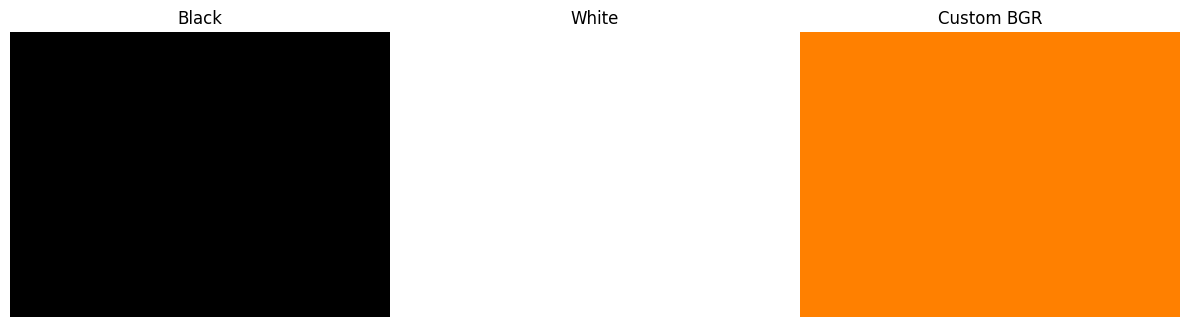

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 建立 300x400 的全黑畫布 (高 H=300, 寬 W=400, 3通道 BGR)
black_canvas = np.zeros((300, 400, 3), dtype=np.uint8)

# 2. 建立全白畫布
white_canvas = np.full((300, 400, 3), 255, dtype=np.uint8)

# 3. 建立自訂顏色畫布 (BGR 順序,這裡以橘色為例)
custom_canvas = np.zeros((300, 400, 3), dtype=np.uint8)
custom_canvas[:] = (0, 128, 255)   # B=0, G=128, R=255 -> 橘色

# 並列顯示三張畫布
fig, axes = plt.subplots(1, 3, figsize=(12, 4))   # 改成 1x3
for ax, img, name in zip(axes,
              [black_canvas, white_canvas, custom_canvas],
              ["Black", "White", "Custom BGR"]):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(name)
    ax.axis("off")   # 隱藏座標軸(可選)

plt.tight_layout()
plt.show()


# 2.幾何圖形繪製 (Drawing Basic Shapes)


## 線條 (Line)

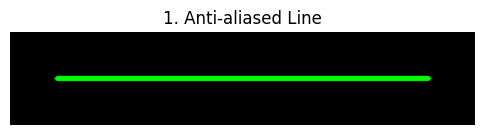

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

canvas = np.zeros((100, 500, 3), dtype=np.uint8)

cv2.line(canvas, (50, 50), (450, 50),
    color=(0, 255, 0),
    thickness=4,
    lineType=cv2.LINE_AA)

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))   # img 改成 canvas
plt.title("1. Anti-aliased Line")            # title 直接寫字串
plt.axis("off")
plt.show()


## 矩形 (Rectangle)

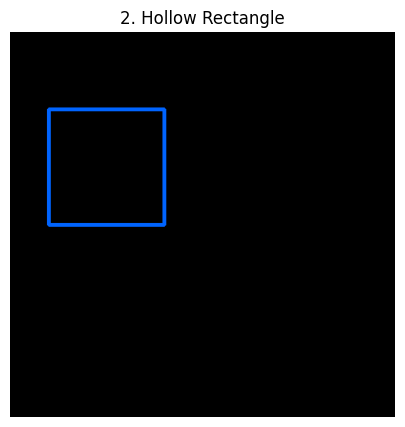

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

canvas = np.zeros((500, 500, 3), dtype=np.uint8)

cv2.rectangle(canvas, (50, 100), (200, 250),
       color=(255, 100, 0),  # BGR: B=255 -> 偏藍色
       thickness=3)

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))   # img 改成 canvas
plt.title("2. Hollow Rectangle")            # title 直接寫字串
plt.axis("off")
plt.show()

## 圓形與圓環 (Circle)

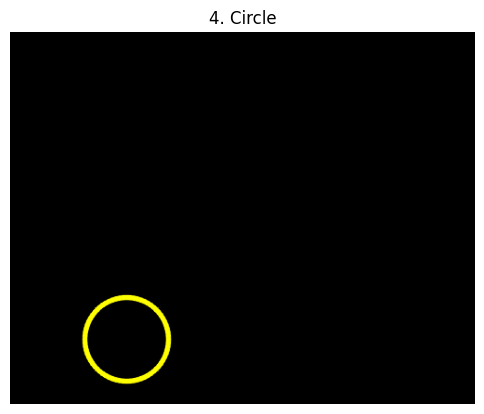

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

canvas = np.zeros((400, 500, 3), dtype=np.uint8)

cv2.circle(canvas, (125, 330),
      radius=45,
      color=(0, 255, 255),     # BGR: 黃色 (綠 + 紅)
      thickness=3,
      lineType=cv2.LINE_AA)

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))   # img 改成 canvas
plt.title("4. Circle")            # title 直接寫字串
plt.axis("off")
plt.show()

## 橢圓與扇形 (Ellipse)

## 箭頭線 (ArrowedLine)

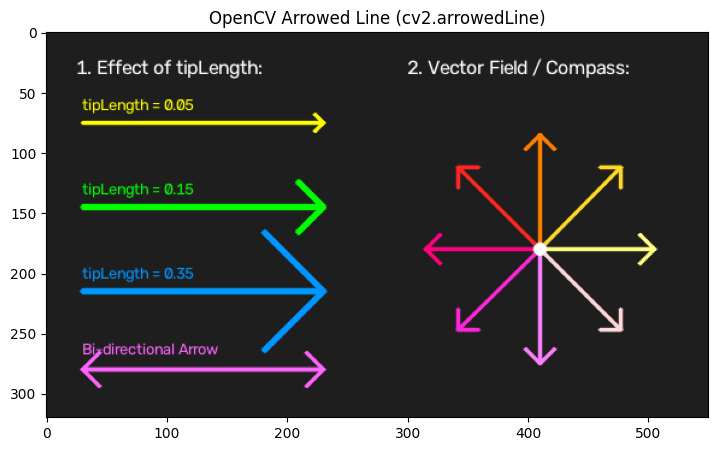

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 建立 320x550 的深色背景畫布
img = np.zeros((320, 550, 3), dtype=np.uint8)
img[:, :] = (30, 30, 30)

font = cv2.FONT_HERSHEY_SIMPLEX

# ==========================================
# 1. 左半部：比較不同 tipLength (箭頭尖端長度比例)
# ==========================================
cv2.putText(img, "1. Effect of tipLength:", (25, 35), font, 0.55, (255, 255, 255), 1, cv2.LINE_AA)

# (a) tipLength = 0.05 (小箭頭)
cv2.arrowedLine(img, (30, 75), (230, 75), (0, 255, 255), thickness=2, line_type=cv2.LINE_AA, tipLength=0.05)
cv2.putText(img, "tipLength = 0.05", (30, 65), font, 0.45, (0, 255, 255), 1, cv2.LINE_AA)

# (b) tipLength = 0.15 (預設適中大小)
cv2.arrowedLine(img, (30, 145), (230, 145), (0, 255, 0), thickness=3, line_type=cv2.LINE_AA, tipLength=0.15)
cv2.putText(img, "tipLength = 0.15", (30, 135), font, 0.45, (0, 255, 0), 1, cv2.LINE_AA)

# (c) tipLength = 0.35 (大箭頭)
cv2.arrowedLine(img, (30, 215), (230, 215), (255, 150, 0), thickness=4, line_type=cv2.LINE_AA, tipLength=0.35)
cv2.putText(img, "tipLength = 0.35", (30, 205), font, 0.45, (255, 150, 0), 1, cv2.LINE_AA)

# (d) 雙向箭頭技巧：起終點互換畫兩次
cv2.arrowedLine(img, (30, 280), (230, 280), (255, 100, 255), 2, cv2.LINE_AA, tipLength=0.1)
cv2.arrowedLine(img, (230, 280), (30, 280), (255, 100, 255), 2, cv2.LINE_AA, tipLength=0.1)
cv2.putText(img, "Bi-directional Arrow", (30, 268), font, 0.45, (255, 100, 255), 1, cv2.LINE_AA)


# ==========================================
# 2. 右半部：實戰應用 — 中心發散向量羅盤 (Vector Compass)
# ==========================================
cv2.putText(img, "2. Vector Field / Compass:", (300, 35), font, 0.55, (255, 255, 255), 1, cv2.LINE_AA)

cx, cy = 410, 180
radius = 95

# 每隔 45 度畫一條向外發散的向量箭頭
for angle in range(0, 360, 45):
    rad = np.deg2rad(angle)
    end_x = int(cx + radius * np.cos(rad))
    end_y = int(cy + radius * np.sin(rad))

    # 依角度自動變化顏色
    color = (int(128 + 127 * np.sin(rad)), int(128 + 127 * np.cos(rad)), 255)
    cv2.arrowedLine(img, (cx, cy), (end_x, end_y), color, thickness=2, line_type=cv2.LINE_AA, tipLength=0.18)

# 中心點標記
cv2.circle(img, (cx, cy), 5, (255, 255, 255), -1, cv2.LINE_AA)

# ==========================================
# 使用 Matplotlib 顯示
# ==========================================
plt.figure(figsize=(9, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("OpenCV Arrowed Line (cv2.arrowedLine)")
plt.axis("on")
plt.show()


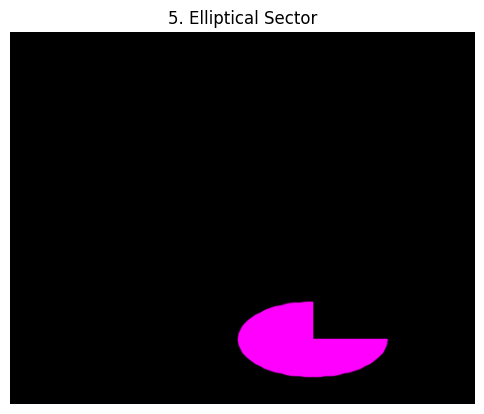

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

canvas = np.zeros((400, 500, 3), dtype=np.uint8)

cv2.ellipse(canvas,
      center=(325, 330),
      axes=(80, 40),       # (長半軸, 短半軸)
      angle=0,           # 橢圓整體旋轉角度
      startAngle=0,         # 起始角度
      endAngle=270,         # 結束角度
      color=(255, 0, 255),    # BGR: 紫色 (藍 + 紅)
      thickness=-1,         # 實心 -> 扇形
      lineType=cv2.LINE_AA)

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))   # img 改成 canvas
plt.title("5. Elliptical Sector")            # title 直接寫字串
plt.axis("off")
plt.show()

## 定位標記符號 (Markers)

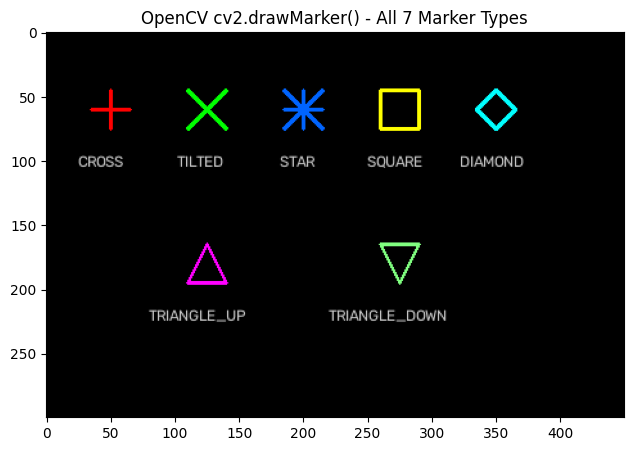

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 建立一張黑色背景的影像 (高 H=300, 寬 W=450)
img = np.zeros((300, 450, 3), dtype=np.uint8)

# 1. 第一排：你原本的 5 種標記 (十字、斜十字、星號、正方形、菱形)
cv2.drawMarker(img, (50, 60), (0, 0, 255), markerType=cv2.MARKER_CROSS, markerSize=30, thickness=2)
cv2.drawMarker(img, (125, 60), (0, 255, 0), markerType=cv2.MARKER_TILTED_CROSS, markerSize=30, thickness=2)
cv2.drawMarker(img, (200, 60), (255, 100, 0), markerType=cv2.MARKER_STAR, markerSize=30, thickness=2)
cv2.drawMarker(img, (275, 60), (0, 255, 255), markerType=cv2.MARKER_SQUARE, markerSize=30, thickness=2)
cv2.drawMarker(img, (350, 60), (255, 255, 0), markerType=cv2.MARKER_DIAMOND, markerSize=30, thickness=2)

# 2. 第二排：補充另外 2 種內建三角形標記 (向上三角形、向下三角形)
cv2.drawMarker(img, (125, 180), (255, 0, 255), markerType=cv2.MARKER_TRIANGLE_UP, markerSize=30, thickness=2)
cv2.drawMarker(img, (275, 180), (128, 255, 128), markerType=cv2.MARKER_TRIANGLE_DOWN, markerSize=30, thickness=2)

# 加上文字名稱對照，方便講義閱讀
font = cv2.FONT_HERSHEY_SIMPLEX
cv2.putText(img, "CROSS", (25, 105), font, 0.4, (200, 200, 200), 1, cv2.LINE_AA)
cv2.putText(img, "TILTED", (102, 105), font, 0.4, (200, 200, 200), 1, cv2.LINE_AA)
cv2.putText(img, "STAR", (182, 105), font, 0.4, (200, 200, 200), 1, cv2.LINE_AA)
cv2.putText(img, "SQUARE", (250, 105), font, 0.4, (200, 200, 200), 1, cv2.LINE_AA)
cv2.putText(img, "DIAMOND", (322, 105), font, 0.4, (200, 200, 200), 1, cv2.LINE_AA)
cv2.putText(img, "TRIANGLE_UP", (80, 225), font, 0.4, (200, 200, 200), 1, cv2.LINE_AA)
cv2.putText(img, "TRIANGLE_DOWN", (220, 225), font, 0.4, (200, 200, 200), 1, cv2.LINE_AA)

# ==========================================
# 使用 Matplotlib 顯示影像 (記得 BGR 轉 RGB)
# ==========================================
plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("OpenCV cv2.drawMarker() - All 7 Marker Types")
plt.axis("on")  # 顯示座標軸刻度以對照 (x, y) 位置
plt.show()


# 3.複雜形狀與自定義多邊形 (Polygons)


## 任意折線 (Polyline)

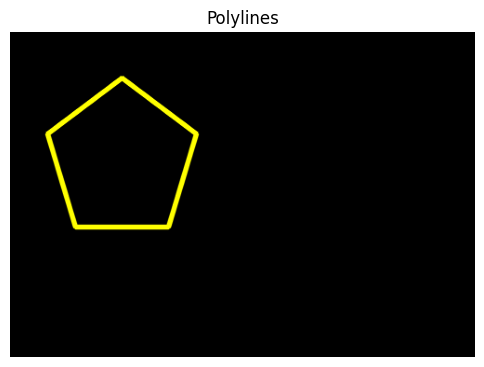

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

canvas = np.zeros((350, 500, 3), dtype=np.uint8)

# 1. 定義空心五邊形的頂點座標 (x, y)
pts_pentagon = np.array([[120, 50], [200, 110], [170, 210], [70, 210], [40, 110]], dtype=np.int32)
pts_pentagon = pts_pentagon.reshape((-1, 1, 2))
cv2.polylines(canvas, [pts_pentagon], isClosed=True, color=(0, 255, 255), thickness=3, lineType=cv2.LINE_AA)

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))   # img 改成 canvas
plt.title("Polylines")            # title 直接寫字串
plt.axis("off")
plt.show()

## 任意多邊形 (Filled Polygon)

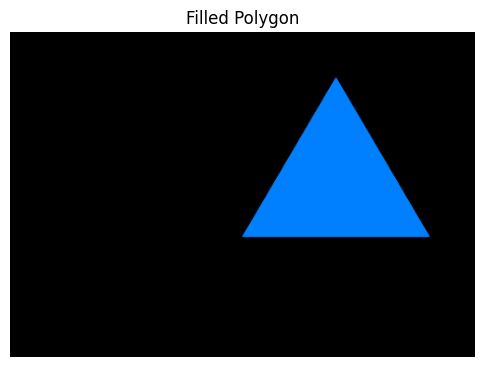

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

canvas = np.zeros((350, 500, 3), dtype=np.uint8)

# 2. 定義實心三角形的頂點座標
pts_triangle = np.array([[350, 50], [450, 220], [250, 220]], dtype=np.int32)
cv2.fillPoly(canvas, [pts_triangle], color=(255, 128, 0), lineType=cv2.LINE_AA)

plt.figure(figsize=(6, 5))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))   # img 改成 canvas
plt.title("Filled Polygon")               # title 直接寫字串
plt.axis("off")
plt.show()

## 僅限 凸多邊形 (FillConvexPoly)（三角形、車道梯形等）

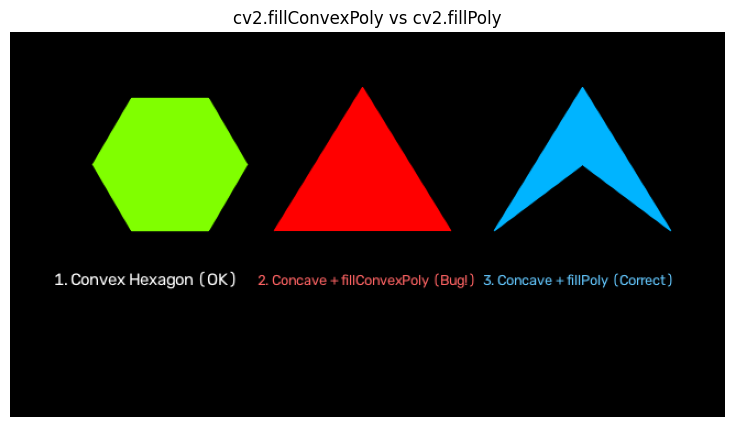

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

canvas = np.zeros((350, 650, 3), dtype=np.uint8)

# ==========================================
# 1. 正確示範：使用 fillConvexPoly 畫凸六邊形
# ==========================================
hexagon_pts = np.array([
    [110, 60], [180, 60], [215, 120],
    [180, 180], [110, 180], [75, 120]
], dtype=np.int32)

# 注意：直接傳入 hexagon_pts，不需要加中括號 [hexagon_pts]
cv2.fillConvexPoly(canvas, hexagon_pts, color=(0, 255, 128), lineType=cv2.LINE_AA)
cv2.putText(canvas, "1. Convex Hexagon (OK)", (40, 230),
            cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)

# ==========================================
# 2. 對比實驗：畫一個向內凹的「V型迴力鏢 (凹多邊形)」
# ==========================================
# 頂點包含向內凹陷的點 (320, 120)
concave_pts1 = np.array([
    [320, 50], [400, 180], [320, 120], [240, 180]
], dtype=np.int32)

# (A) 錯誤使用 fillConvexPoly -> 凹陷處會破圖或填滿異常
cv2.fillConvexPoly(canvas, concave_pts1, color=(0, 0, 255), lineType=cv2.LINE_AA)
cv2.putText(canvas, "2. Concave + fillConvexPoly (Bug!)", (225, 230),
            cv2.FONT_HERSHEY_SIMPLEX, 0.45, (100, 100, 255), 1, cv2.LINE_AA)

# (B) 正確使用 fillPoly -> 完美保留凹陷形狀 (座標向右平移 200 像素)
concave_pts2 = concave_pts1 + np.array([200, 0], dtype=np.int32)
cv2.fillPoly(canvas, [concave_pts2], color=(255, 180, 0), lineType=cv2.LINE_AA)
cv2.putText(canvas, "3. Concave + fillPoly (Correct)", (430, 230),
            cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 200, 100), 1, cv2.LINE_AA)

# 顯示影像
plt.figure(figsize=(10, 5))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
plt.title("cv2.fillConvexPoly vs cv2.fillPoly")
plt.axis("off")
plt.show()


# 4.文字繪製與中文支援解決方案 (Drawing Text & Typography)

## OpenCV 內建英文字型

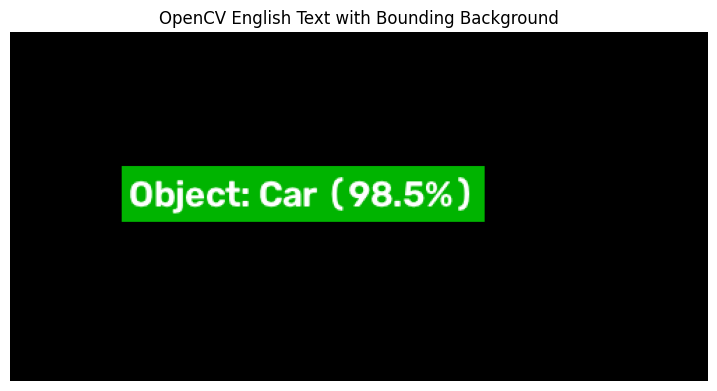

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

canvas = np.zeros((250, 500, 3), dtype=np.uint8)
text = "Object: Car (98.5%)"
font = cv2.FONT_HERSHEY_SIMPLEX
font_scale = 0.9
thickness = 2

# 計算文字的寬高與基線 (baseline)
(text_w, text_h), baseline = cv2.getTextSize(text, font, font_scale, thickness)

# 設定文字左下角起點 (x, y)
x, y = 80, 130

# 先畫一個貼合文字大小的實心綠色背景框
cv2.rectangle(canvas, (x, y - text_h - 10), (x + text_w + 10, y + baseline), (0, 180, 0), -1)

# 再把白色文字畫在背景框上方
cv2.putText(canvas, text, (x + 5, y - 5), font, font_scale, (255, 255, 255), thickness, cv2.LINE_AA)

# 使用 Matplotlib 顯示最終影像
plt.figure(figsize=(9, 6))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
plt.title("OpenCV English Text with Bounding Background")
plt.axis("off")
plt.show()


## 結合 PIL 繪製中文字串

正在自動下載繁體中文字型 (只需下載一次)...
字型下載完成！


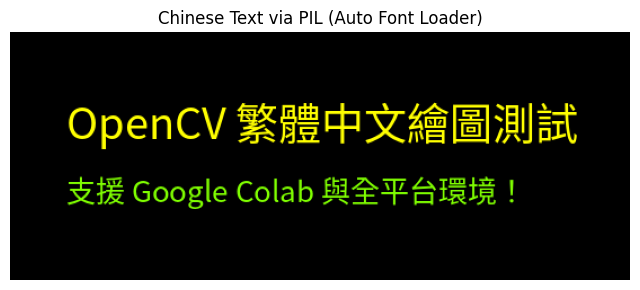

In [ ]:
import os
import urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

def get_chinese_font(font_size=36):
    """自動尋找或下載繁體中文字型 (跨平台相容：Colab / Linux / Windows / Mac)"""
    # 1. 常見系統內建中文字型路徑清單
    font_candidates = [
        "NotoSansTC-Regular.otf",                     # 已下載於當前目錄的字型
        "C:/Windows/Fonts/msjh.ttc",                   # Windows 微軟正黑體
        "C:/Windows/Fonts/mingliu.ttc",                 # Windows 細明體
        "/System/Library/Fonts/PingFang.ttc",             # macOS 蘋方體
        "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc",  # Linux 思源黑體
    ]

    for path in font_candidates:
        if os.path.exists(path):
            return ImageFont.truetype(path, font_size)

    # 2. 若環境中都沒有中文字型 (如 Google Colab 預設環境)，自動下載思源黑體
    font_file = "NotoSansTC-Regular.otf"
    url = "https://github.com/googlefonts/noto-cjk/raw/main/Sans/OTF/TraditionalChinese/NotoSansCJKtc-Regular.otf"
    print("正在自動下載繁體中文字型 (只需下載一次)...")
    urllib.request.urlretrieve(url, font_file)
    print("字型下載完成！")
    return ImageFont.truetype(font_file, font_size)


def put_chinese_text(img_bgr, text, pos, font_size=36, color_bgr=(0, 255, 255)):
    """在 OpenCV 影像上繪製繁體中文"""
    # 1. OpenCV (BGR) -> PIL (RGB)
    img_pil = Image.fromarray(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    draw = ImageDraw.Draw(img_pil)

    # 2. 取得支援中文的 TrueType 字型
    font = get_chinese_font(font_size)

    # 3. 繪製文字 (顏色轉為 RGB)
    color_rgb = (color_bgr[2], color_bgr[1], color_bgr[0])
    draw.text(pos, text, font=font, fill=color_rgb)

    # 4. PIL (RGB) -> OpenCV (BGR)
    return cv2.cvtColor(np.array(img_pil), cv2.COLOR_RGB2BGR)


# ==================== 測試執行 ====================
canvas = np.zeros((220, 550, 3), dtype=np.uint8)

# 繪製兩行不同顏色與大小的繁體中文
canvas = put_chinese_text(canvas, "OpenCV 繁體中文繪圖測試", pos=(50, 50),
               font_size=38, color_bgr=(0, 255, 255))
canvas = put_chinese_text(canvas, "支援 Google Colab 與全平台環境！", pos=(50, 120),
               font_size=26, color_bgr=(0, 255, 128))

# 使用 Matplotlib 顯示
plt.figure(figsize=(8, 4))
plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
plt.title("Chinese Text via PIL (Auto Font Loader)")
plt.axis("off")
plt.show()


# 6.半透明圖形繪製（Alpha Blending 在繪圖的應用）

## AI 視覺半透明資訊面板 (HUD)

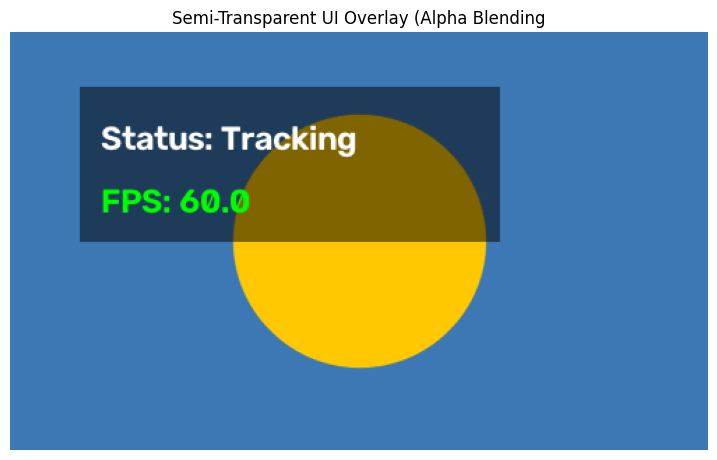

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 建立一張模擬漸層背景圖
img = np.zeros((300, 500, 3), dtype=np.uint8)
img[:, :] = (180, 120, 60)  # 底色
cv2.circle(img, (250, 150), 90, (0, 200, 255), -1, cv2.LINE_AA) # 畫一個亮黃圓當背景物體

# 步驟 1: 複製一份作為半透明圖層
overlay = img.copy()

# 步驟 2: 在 overlay 上畫一個黑色實心矩形 (作為半透明資訊欄底板)
cv2.rectangle(overlay, (50, 40), (350, 150), (0, 0, 0), -1)

# 步驟 3: Alpha 加權融合 (透明度 alpha = 0.5)
alpha = 0.5
result = cv2.addWeighted(overlay, alpha, img, 1 - alpha, 0)

# 在融合後的半透明面板上寫上不透明的亮白文字
cv2.putText(result, "Status: Tracking", (65, 85), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2, cv2.LINE_AA)
cv2.putText(result, "FPS: 60.0", (65, 130), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2, cv2.LINE_AA)

# 使用 Matplotlib 顯示最終影像
plt.figure(figsize=(9, 6))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Semi-Transparent UI Overlay (Alpha Blending")
plt.axis("off")
plt.show()


# 7.滑鼠事件與互動式繪圖 (Mouse Events & Interactive Drawing)

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

def draw_interactive_opencv(shape, x, y, radius_w, height, b, g, r, thickness):
    # 1. 建立 350x500 畫布與格線輔助線
    canvas = np.zeros((350, 500, 3), dtype=np.uint8)
    canvas[:, :] = (30, 30, 30)

    # 畫暗色十字格線方便觀察座標
    for i in range(0, 500, 50):
        cv2.line(canvas, (i, 0), (i, 350), (50, 50, 50), 1)
    for j in range(0, 350, 50):
        cv2.line(canvas, (0, j), (500, j), (50, 50, 50), 1)

    color_bgr = (b, g, r)

    # 2. 根據選單繪製對應 OpenCV 圖形
    if shape == "圓形 (cv2.circle)":
        cv2.circle(canvas, (x, y), radius_w, color_bgr, thickness, cv2.LINE_AA)
        code_str = f"cv2.circle(img, ({x}, {y}), {radius_w}, ({b}, {g}, {r}), {thickness})"

    elif shape == "矩形 (cv2.rectangle)":
        x2, y2 = x + radius_w, y + height
        cv2.rectangle(canvas, (x, y), (x2, y2), color_bgr, thickness, cv2.LINE_AA)
        code_str = f"cv2.rectangle(img, ({x}, {y}), ({x2}, {y2}), ({b}, {g}, {r}), {thickness})"

    elif shape == "橢圓 (cv2.ellipse)":
        cv2.ellipse(canvas, (x, y), (radius_w, height), 0, 0, 360, color_bgr, thickness, cv2.LINE_AA)
        code_str = f"cv2.ellipse(img, ({x}, {y}), ({radius_w}, {height}), 0, 0, 360, ({b}, {g}, {r}), {thickness})"

    # 3. 標示基準點 (紅點) 與即時對應的 OpenCV 程式碼字串
    cv2.circle(canvas, (x, y), 4, (0, 0, 255), -1)
    cv2.putText(canvas, f"Origin ({x}, {y})", (x + 8, y - 8),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45, (150, 150, 255), 1, cv2.LINE_AA)

    # 4. 使用 Matplotlib 顯示並把對應程式碼印在標題上
    plt.figure(figsize=(8, 5))
    plt.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    plt.title(f"{code_str}", fontsize=10, color="navy")
    plt.axis("on")
    plt.show()

# 建立 Colab UI 控制元件
widgets.interact(
    draw_interactive_opencv,
    shape=widgets.Dropdown(options=["圓形 (cv2.circle)", "矩形 (cv2.rectangle)", "橢圓 (cv2.ellipse)"], description="繪圖函式:"),
    x=widgets.IntSlider(min=20, max=450, step=10, value=200, description="X 座標:"),
    y=widgets.IntSlider(min=20, max=300, step=10, value=150, description="Y 座標:"),
    radius_w=widgets.IntSlider(min=10, max=180, step=5, value=80, description="半徑 / 寬度:"),
    height=widgets.IntSlider(min=10, max=180, step=5, value=50, description="高度 (矩形/橢圓):"),
    b=widgets.IntSlider(min=0, max=255, step=15, value=255, description="B (藍):"),
    g=widgets.IntSlider(min=0, max=255, step=15, value=180, description="G (綠):"),
    r=widgets.IntSlider(min=0, max=255, step=15, value=0, description="R (紅):"),
    thickness=widgets.Dropdown(options=[("實心填滿 (-1)", -1), ("細線 (2)", 2), ("中線 (5)", 5), ("粗線 (10)", 10)], value=5, description="線條粗細:")
);


interactive(children=(Dropdown(description='繪圖函式:', options=('圓形 (cv2.circle)', '矩形 (cv2.rectangle)', '橢圓 (cv2…

# 8.綜合實戰小專案

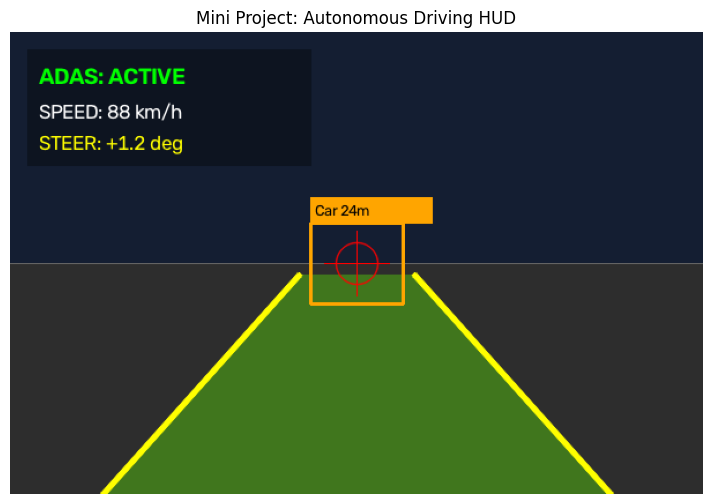

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. 建立 400x600 的標準連續記憶體畫布
hud = np.zeros((400, 600, 3), dtype=np.uint8)

# 繪製背景：上半部深藍夜空 (0~200列)，下半部深灰柏油路 (200~400列)
hud[0:200, :] = (50, 30, 20)     # 夜空底色 (BGR)
hud[200:400, :] = (45, 45, 45)   # 路面底色 (BGR)
cv2.line(hud, (0, 200), (600, 200), (100, 100, 100), 1) # 地平線

# 2. 半透明圖層：繪製「綠色車道導引毯」與「左上角資訊面板底板」
overlay = hud.copy()

# (a) 綠色可行駛車道梯形區域 (注意頂點順序：左上 -> 右上 -> 右下 -> 左下)
lane_pts = np.array([[250, 210], [350, 210], [520, 400], [80, 400]], dtype=np.int32)
lane_pts = lane_pts.reshape((-1, 1, 2))
cv2.fillPoly(overlay, [lane_pts], color=(0, 255, 100))

# (b) 左上角黑色半透明資訊底板
cv2.rectangle(overlay, (15, 15), (260, 115), (0, 0, 0), -1)

# 將 overlay 與 hud 進行 Alpha 融合 (透明度 0.35)
hud = cv2.addWeighted(overlay, 0.35, hud, 0.65, 0)

# 3. 畫車道兩側的高亮邊界線 (黃色抗鋸齒線)
cv2.line(hud, (250, 210), (80, 400), (0, 255, 255), 4, cv2.LINE_AA)
cv2.line(hud, (350, 210), (520, 400), (0, 255, 255), 4, cv2.LINE_AA)

# 4. 模擬前方車輛偵測框 (Bounding Box)
car_x1, car_y1, car_x2, car_y2 = 260, 165, 340, 235
cv2.rectangle(hud, (car_x1, car_y1), (car_x2, car_y2), (0, 165, 255), 2)
# 車輛標籤背景與文字
cv2.rectangle(hud, (car_x1, car_y1 - 22), (car_x2 + 25, car_y1), (0, 165, 255), -1)
cv2.putText(hud, "Car 24m", (car_x1 + 4, car_y1 - 6),
            cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 1, cv2.LINE_AA)

# 5. 畫鏡頭中心準星 (Crosshair)
cx, cy = 300, 200
cv2.circle(hud, (cx, cy), 18, (0, 0, 255), 1, cv2.LINE_AA)
cv2.line(hud, (cx - 28, cy), (cx + 28, cy), (0, 0, 255), 1)
cv2.line(hud, (cx, cy - 28), (cx, cy + 28), (0, 0, 255), 1)

# 6. 左上角儀表板文字資訊
cv2.putText(hud, "ADAS: ACTIVE", (25, 45), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (0, 255, 0), 2, cv2.LINE_AA)
cv2.putText(hud, "SPEED: 88 km/h", (25, 75), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1, cv2.LINE_AA)
cv2.putText(hud, "STEER: +1.2 deg", (25, 102), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 1, cv2.LINE_AA)

# 7. 使用 Matplotlib 顯示最終影像
plt.figure(figsize=(9, 6))
plt.imshow(cv2.cvtColor(hud, cv2.COLOR_BGR2RGB))
plt.title("Mini Project: Autonomous Driving HUD")
plt.axis("off")
plt.show()
